# Análise de falhas em equipamentos industriais
### Projeto de Data Science e Big Data

---

| Identificação | Dados |
| :--- | :--- |
| **Aluno** | Carlos Alexandre Duarte Pereira |
| **Curso** | Data Science & Big Data Aplicados na Indústria |
| **Disciplina** | Data Science e Big Data |
| **Professor** | Me. Daniel Vieira |
| **Semestre** | 1º Semestre 2026 |
| **Data** | 24/10/2026 |

---

## Introdução
A S&M Industry Tech enfrenta problemas com paradas não planejadas de equipamentos.
O objetivo deste trabalho é analisar os dados de operação das máquinas, identificar
condições associadas às falhas e comparar modelos de classificação.

A análise está dividida em cinco etapas: exploração dos dados, preparação,
classificação supervisionada, agrupamento com K-Means e processamento com PySpark.
A variável `falha` representa a ocorrência no registro, sendo 0 para ausência de
falha e 1 para presença de falha.


## Bibliotecas e base de dados
As análises utilizam Pandas, NumPy, Matplotlib, Seaborn e scikit-learn.
O PySpark é utilizado na etapa de processamento dos dados e o gdown no acesso
à base disponibilizada para o projeto.


In [1]:
import sys
import subprocess
try:
    import google.colab
    no_colab = True
except ImportError:
    no_colab = False

if no_colab:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "pyspark==4.0.1", "gdown>=5.2,<6"])


In [2]:
# Importação das bibliotecas
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             confusion_matrix, silhouette_score)
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans

SEMENTE = 42  # facilita repetir os resultados
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 20)
Path("resultados").mkdir(exist_ok=True)


In [3]:
# Leitura da base de manutenção
arquivo = Path("data/dados_manutencao.csv")
if not arquivo.exists():
    arquivo = Path("dados_manutencao.csv")
if not arquivo.exists():
    import gdown
    gdown.download(id="1yQ7P-mbRK3Gsh12ey6ahxk8szc6pOie1",
                   output=str(arquivo), quiet=False)
if not arquivo.exists():
    raise FileNotFoundError("Arquivo dados_manutencao.csv não encontrado.")

df = pd.read_csv(arquivo)
colunas_esperadas = ["timestamp", "maquina_id", "temperatura_c", "vibracao_mm_s",
                    "pressao_bar", "corrente_a", "horas_operacao", "falha"]
assert set(colunas_esperadas).issubset(df.columns), "A base não contém todas as colunas esperadas."
display(df.head())


,timestamp,maquina_id,temperatura_c,vibracao_mm_s,pressao_bar,corrente_a,horas_operacao,falha
0,2026-02-05 18:00:00,M04,61.97,3.37,5.59,22.48,10154.0,0
1,2026-01-22 13:00:00,M01,60.86,2.07,6.55,23.21,2687.0,0
2,2026-01-17 05:00:00,M03,70.35,2.75,6.21,26.36,11779.0,0
3,2026-01-19 16:00:00,M02,68.22,3.55,7.23,28.03,4519.0,0
4,2026-02-07 21:00:00,M01,73.89,2.64,5.89,25.73,9899.0,0


# Etapa 1 — Compreensão e exploração dos dados
A exploração inicial apresenta a quantidade de registros, os tipos das variáveis,
as distribuições das medições e a proporção de falhas por máquina. Os resultados
desta etapa correspondem ao arquivo original, antes da retirada das duplicatas.


In [4]:
print(f"Quantidade de linhas: {len(df)} | Quantidade de colunas: {len(df.columns)}")
df.info()
display(df.describe().round(2))


Quantidade de linhas: 5050 | Quantidade de colunas: 8
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   timestamp       5050 non-null   object 
 1   maquina_id      5050 non-null   object 
 2   temperatura_c   4998 non-null   float64
 3   vibracao_mm_s   5000 non-null   float64
 4   pressao_bar     4999 non-null   float64
 5   corrente_a      5000 non-null   float64
 6   horas_operacao  4999 non-null   float64
 7   falha           5050 non-null   int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 315.8+ KB


,temperatura_c,vibracao_mm_s,pressao_bar,corrente_a,horas_operacao,falha
count,4998.00,5000.00,4999.00,5000.00,4999.00,5050.00
mean,67.12,3.06,6.50,25.68,6092.11,0.18
std,12.50,0.90,0.65,2.71,3438.01,0.38
min,41.33,0.23,4.25,14.81,102.00,0.00
25%,61.59,2.52,6.07,23.85,3086.00,0.00
50%,66.53,3.03,6.50,25.68,6120.00,0.00
75%,71.39,3.54,6.94,27.44,9003.50,0.00
max,278.84,15.12,9.16,35.33,11999.00,1.00


## Dicionário dos dados
| Coluna | Significado | Tipo esperado / uso |
|---|---|---|
| timestamp | Data e hora da observação | Data; usada para ordenar e separar os períodos |
| maquina_id | Identificação do equipamento | Categoria; usada para comparar máquinas |
| temperatura_c | Temperatura em °C | Numérica; atributo do modelo |
| vibracao_mm_s | Vibração em mm/s | Numérica; atributo do modelo |
| pressao_bar | Pressão em bar | Numérica; atributo do modelo |
| corrente_a | Corrente elétrica em A | Numérica; atributo do modelo |
| horas_operacao | Horas de operação registradas | Numérica; atributo do modelo |
| falha | Ocorrência de falha | Classe binária: 0 ou 1 |

O CSV inicialmente carrega a data como texto. A conversão será feita na etapa 2.


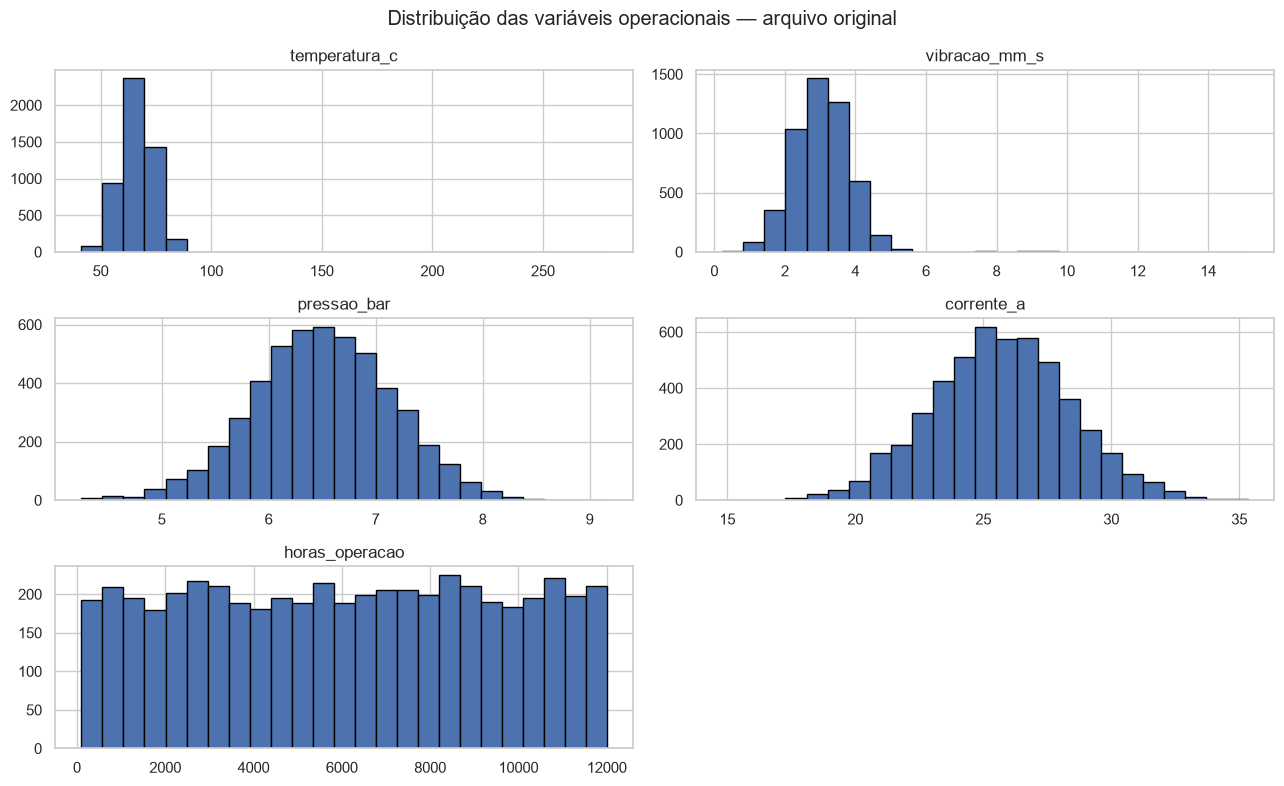

,registros,percentual
falha,,
0,4144,82.06
1,906,17.94


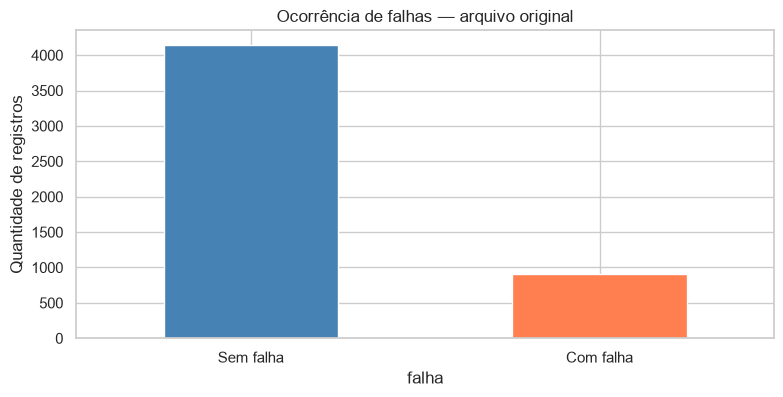

No arquivo original: 906 falhas (17.94%).


In [5]:
numericas = ["temperatura_c", "vibracao_mm_s", "pressao_bar", "corrente_a", "horas_operacao"]
df[numericas].hist(bins=25, figsize=(13, 8), edgecolor="black")
plt.suptitle("Distribuição das variáveis operacionais — arquivo original")
plt.tight_layout()
plt.show()

contagem_falhas = df["falha"].value_counts().sort_index()
display(pd.DataFrame({"registros": contagem_falhas,
                      "percentual": (contagem_falhas / len(df) * 100).round(2)}))
contagem_falhas.rename(index={0: "Sem falha", 1: "Com falha"}).plot(kind="bar", color=["steelblue", "coral"])
plt.ylabel("Quantidade de registros")
plt.title("Ocorrência de falhas — arquivo original")
plt.xticks(rotation=0)
plt.show()
print(f"No arquivo original: {df['falha'].sum()} falhas ({df['falha'].mean():.2%}).")


In [6]:
taxas_originais = df.groupby("maquina_id")["falha"].agg(registros="count", falhas="sum", taxa="mean")
display(taxas_originais.sort_values("taxa", ascending=False).round(4))
print("Maior taxa no arquivo original:", taxas_originais["taxa"].idxmax())


,registros,falhas,taxa
maquina_id,,,
M04,1014,192,0.1893
M03,1007,181,0.1797
M05,1008,180,0.1786
M02,1009,178,0.1764
M01,1012,175,0.1729


Maior taxa no arquivo original: M04


## Análise inicial
O arquivo contém 5.050 registros e 8 colunas. Há 906 registros com falha,
aproximadamente 17,94% do total. A máquina M04 apresenta a maior taxa no arquivo
original, com cerca de 18,93%.

A classe sem falha é mais frequente. Por isso, a acurácia precisa ser analisada
junto com precisão, recall e F1-score. Um modelo que classificasse todos os registros
como sem falha teria muitos acertos, mas não identificaria nenhuma das falhas.

A comparação entre máquinas considera a taxa de falha, calculada pela divisão
do número de registros com falha pelo total de registros de cada equipamento.


# Etapa 2 — Preparação e mineração de dados
A preparação inclui a remoção de duplicatas exatas, a conversão da coluna de data
e a verificação de valores ausentes e extremos. Temperaturas e vibrações elevadas
são mantidas na base, pois podem representar condições relevantes para a análise.

Nos classificadores, os valores ausentes são preenchidos com a mediana calculada
somente nos dados de treinamento, por meio de um `Pipeline`.


,ausentes_no_original
timestamp,0
maquina_id,0
temperatura_c,52
vibracao_mm_s,50
pressao_bar,51
corrente_a,50
horas_operacao,51
falha,0


Duplicatas exatas removidas: 50
Registros após limpeza: 5000
Período: 2026-01-01 00:00:00 até 2026-02-11 15:00:00


,ausentes_apos_duplicatas
timestamp,0
maquina_id,0
temperatura_c,50
vibracao_mm_s,50
pressao_bar,50
corrente_a,50
horas_operacao,50
falha,0


,registros,falhas,taxa
maquina_id,,,
M04,1000,189,0.189
M03,1000,181,0.181
M05,1000,180,0.180
M02,1000,178,0.178
M01,1000,175,0.175


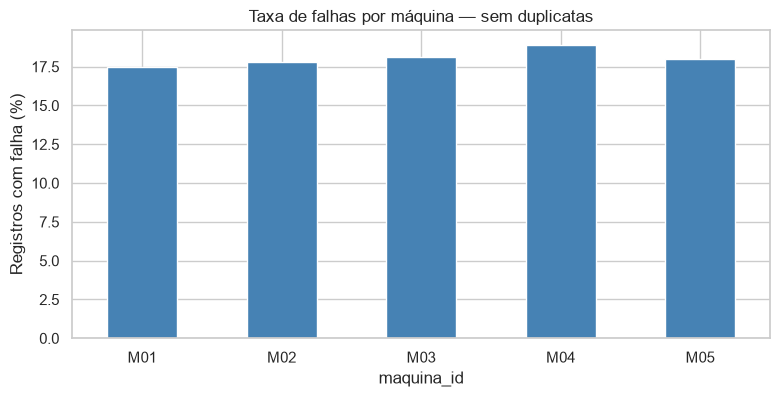

**Após a limpeza:** 5,000 registros, 903 com falha (18.06%). A maior taxa observada é da máquina **M04**, com **18.90%**. Essa diferença descritiva, sozinha, não prova que uma máquina seja menos confiável.

In [7]:
display(df.isna().sum().rename("ausentes_no_original").to_frame())
duplicadas = int(df.duplicated().sum())
df1 = df.drop_duplicates().copy()
df1["timestamp"] = pd.to_datetime(df1["timestamp"], errors="coerce")
assert df1["timestamp"].notna().all(), "A base contém datas inválidas."
assert df1["falha"].notna().all() and set(df1["falha"].unique()) == {0, 1}
assert not df1.duplicated(["maquina_id", "timestamp"]).any(), "Há registros diferentes para a mesma máquina e instante."
df1 = df1.sort_values(["timestamp", "maquina_id"]).reset_index(drop=True)
print("Duplicatas exatas removidas:", duplicadas)
print("Registros após limpeza:", len(df1))
print("Período:", df1["timestamp"].min(), "até", df1["timestamp"].max())
display(df1.isna().sum().rename("ausentes_apos_duplicatas").to_frame())

taxas = df1.groupby("maquina_id")["falha"].agg(registros="count", falhas="sum", taxa="mean")
display(taxas.sort_values("taxa", ascending=False).round(4))
taxas["taxa"].mul(100).plot(kind="bar", color="steelblue")
plt.ylabel("Registros com falha (%)")
plt.title("Taxa de falhas por máquina — sem duplicatas")
plt.xticks(rotation=0)
plt.show()
display(Markdown(f"**Após a limpeza:** {len(df1):,} registros, {int(df1.falha.sum())} com falha "
                 f"({df1.falha.mean():.2%}). A maior taxa observada é da máquina "
                 f"**{taxas.taxa.idxmax()}**, com **{taxas.taxa.max():.2%}**. "
                 "Essa diferença descritiva, sozinha, não prova que uma máquina seja menos confiável."))


,mínimo,máximo,extremos_IQR
temperatura_c,41.33,278.84,49
vibracao_mm_s,0.23,15.12,68
pressao_bar,4.25,9.16,40
corrente_a,14.81,35.33,37
horas_operacao,102.00,11999.00,0


Valores negativos para investigar:


,quantidade
temperatura_c,0
vibracao_mm_s,0
pressao_bar,0
corrente_a,0
horas_operacao,0


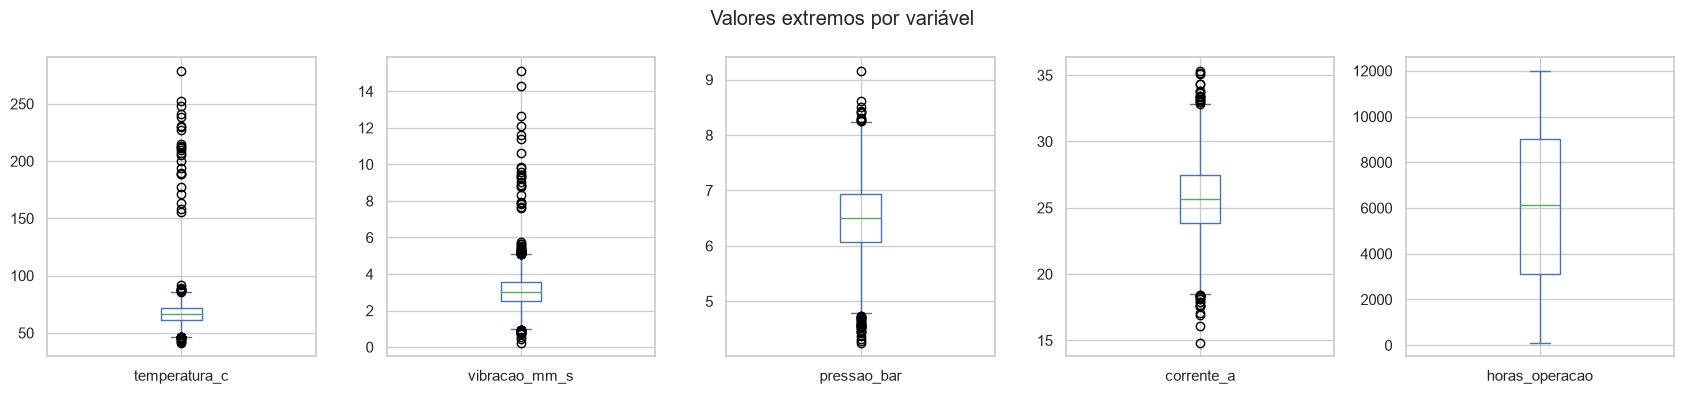

In [8]:
# IQR: regra estatística para sinalizar extremos, não um limite de segurança industrial
q1 = df1[numericas].quantile(0.25)
q3 = df1[numericas].quantile(0.75)
iqr = q3 - q1
extremos = (df1[numericas] < q1 - 1.5 * iqr) | (df1[numericas] > q3 + 1.5 * iqr)
display(pd.DataFrame({"mínimo": df1[numericas].min(), "máximo": df1[numericas].max(),
                      "extremos_IQR": extremos.sum()}).round(2))
print("Valores negativos para investigar:")
display((df1[numericas] < 0).sum().to_frame("quantidade"))
df1[numericas].plot(kind="box", subplots=True, layout=(1, 5), figsize=(17, 4), sharey=False)
plt.suptitle("Valores extremos por variável")
plt.tight_layout()
plt.show()


## Tratamento dos problemas encontrados
Foram removidas 50 duplicatas exatas, restando 5.000 registros. Após essa remoção,
cada uma das cinco variáveis operacionais apresentou 50 valores ausentes. As colunas
de data, identificação da máquina e falha não apresentaram ausências.

A mediana foi escolhida para o preenchimento nos modelos por ser menos sensível
a valores extremos que a média. Na análise descritiva, os valores ausentes foram
mantidos e desconsiderados pelo Pandas nos cálculos de médias e correlações.

O intervalo interquartil (IQR) foi utilizado para sinalizar possíveis outliers.
Esses registros não foram excluídos, pois a base não fornece os limites de operação
de cada equipamento. A temperatura máxima de 278,84 °C, por exemplo, precisa ser
verificada para distinguir uma condição real de um possível erro de medição.


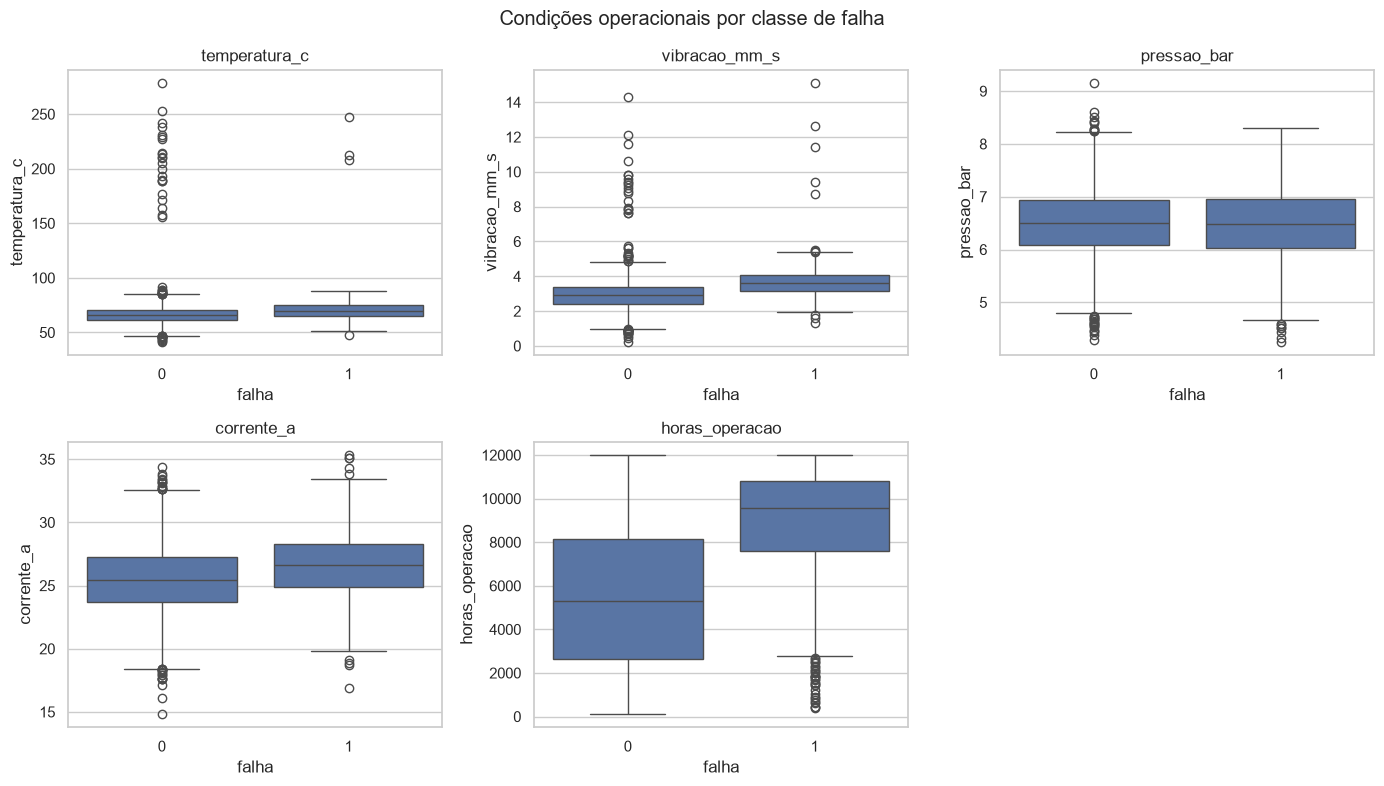

temperatura_c        vibracao_mm_s        pressao_bar        corrente_a  \
               mean median          mean median        mean median       mean   
falha                                                                           
0             66.46  65.87          2.93   2.91        6.51   6.51      25.46   
1             70.11  69.68          3.64   3.60        6.47   6.48      26.61   

             horas_operacao          
      median           mean  median  
falha                                
0      25.47        5483.84  5280.5  
1      26.60        8887.35  9547.5

In [9]:
# Comparação das medições entre registros sem falha e com falha
fig, eixos = plt.subplots(2, 3, figsize=(14, 8))
for coluna, eixo in zip(numericas, eixos.flat):
    sns.boxplot(data=df1, x="falha", y=coluna, ax=eixo)
    eixo.set_title(coluna)
eixos.flat[-1].set_visible(False)
plt.suptitle("Condições operacionais por classe de falha")
plt.tight_layout()
plt.show()
display(df1.groupby("falha")[numericas].agg(["mean", "median"]).round(2))


In [10]:
# Faixas por quartis: ajudam a visualizar a frequência de falhas em cada condição
associacoes = []
for coluna in numericas:
    faixas = pd.qcut(df1[coluna], q=4, duplicates="drop")
    resumo_faixas = df1.groupby(faixas, observed=True)["falha"].agg(
        registros="count", falhas="sum", taxa="mean")
    print("\nVariável:", coluna)
    display(resumo_faixas.round(4))
    associacoes.append({"variavel": coluna,
                        "taxa_menor_faixa": resumo_faixas["taxa"].iloc[0],
                        "taxa_maior_faixa": resumo_faixas["taxa"].iloc[-1]})
display(pd.DataFrame(associacoes).round(4))
for item in associacoes:
    diferenca = item["taxa_maior_faixa"] - item["taxa_menor_faixa"]
    sentido = "maior" if diferenca > 0 else "menor ou igual"
    print(f"{item['variavel']}: a taxa na faixa mais alta foi {item['taxa_maior_faixa']:.2%}, "
          f"contra {item['taxa_menor_faixa']:.2%} na faixa mais baixa ({sentido}).")
print("As faixas são descritivas, excluem os ausentes de cada sensor e não são limites de alarme.")



Variável: temperatura_c


,registros,falhas,taxa
temperatura_c,,,
"(41.329, 61.572]",1238,120,0.0969
"(61.572, 66.515]",1237,180,0.1455
"(66.515, 71.39]",1240,232,0.1871
"(71.39, 278.84]",1235,358,0.2899



Variável: vibracao_mm_s


,registros,falhas,taxa
vibracao_mm_s,,,
"(0.229, 2.52]",1251,47,0.0376
"(2.52, 3.03]",1243,127,0.1022
"(3.03, 3.54]",1231,244,0.1982
"(3.54, 15.12]",1225,478,0.3902



Variável: pressao_bar


...

,registros,falhas,taxa
corrente_a,,,
"(14.809000000000001, 23.85]",1242,140,0.1127
"(23.85, 25.68]",1240,188,0.1516
"(25.68, 27.44]",1233,246,0.1995
"(27.44, 35.33]",1235,319,0.2583



Variável: horas_operacao


,registros,falhas,taxa
horas_operacao,,,
"(101.999, 3092.25]",1238,37,0.0299
"(3092.25, 6122.0]",1238,93,0.0751
"(6122.0, 9016.75]",1236,251,0.2031
"(9016.75, 11999.0]",1238,513,0.4144


,variavel,taxa_menor_faixa,taxa_maior_faixa
0,temperatura_c,0.0969,0.2899
1,vibracao_mm_s,0.0376,0.3902
2,pressao_bar,0.1944,0.1852
3,corrente_a,0.1127,0.2583
4,horas_operacao,0.0299,0.4144


temperatura_c: a taxa na faixa mais alta foi 28.99%, contra 9.69% na faixa mais baixa (maior).
vibracao_mm_s: a taxa na faixa mais alta foi 39.02%, contra 3.76% na faixa mais baixa (maior).
pressao_bar: a taxa na faixa mais alta foi 18.52%, contra 19.44% na faixa mais baixa (menor ou igual).
corrente_a: a taxa na faixa mais alta foi 25.83%, contra 11.27% na faixa mais baixa (maior).
horas_operacao: a taxa na faixa mais alta foi 41.44%, contra 2.99% na faixa mais baixa (maior).
As faixas são descritivas, excluem os ausentes de cada sensor e não são limites de alarme.


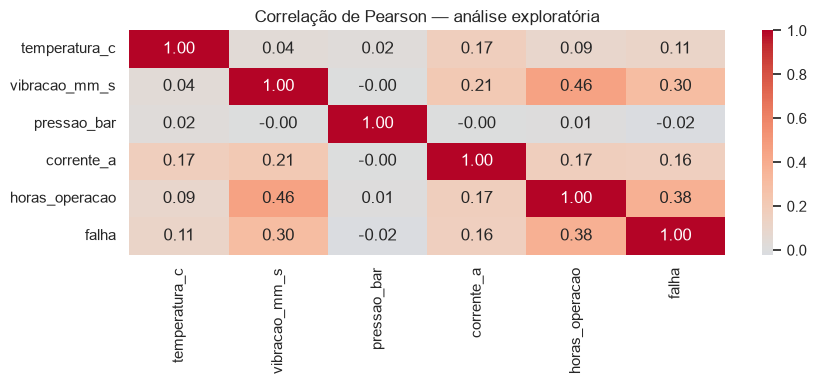

,correlacao_com_falha
horas_operacao,0.381
vibracao_mm_s,0.304
corrente_a,0.163
temperatura_c,0.112
pressao_bar,-0.022


A maior correlação linear em valor absoluto com falha foi de **horas_operacao** (0.381). Os boxplots e as taxas por faixa complementam esse resultado: uma correlação baixa pode esconder relações não lineares. Associação não demonstra causa e efeito.

In [11]:
correlacoes = df1[numericas + ["falha"]].corr()
sns.heatmap(correlacoes, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação de Pearson — análise exploratória")
plt.tight_layout()
plt.show()
correlacao_falha = correlacoes["falha"].drop("falha").sort_values(key=abs, ascending=False)
display(correlacao_falha.rename("correlacao_com_falha").to_frame().round(3))
display(Markdown(f"A maior correlação linear em valor absoluto com falha foi de "
                 f"**{correlacao_falha.index[0]}** ({correlacao_falha.iloc[0]:.3f}). "
                 "Os boxplots e as taxas por faixa complementam esse resultado: "
                 "uma correlação baixa pode esconder relações não lineares. "
                 "Associação não demonstra causa e efeito."))


# Etapa 3 — Machine Learning supervisionado
## Seleção dos atributos e divisão da base
Os atributos utilizados foram temperatura, vibração, pressão, corrente elétrica
e horas de operação. Essas variáveis descrevem as condições de funcionamento dos
equipamentos. A coluna `falha` foi utilizada apenas como variável alvo.

O identificador da máquina ficou fora do treinamento para concentrar a análise
nas medições operacionais. A data foi utilizada para separar os períodos.

A divisão seguiu a ordem temporal: **60% das datas para treino, 20% para validação
e 20% para teste**. Os registros do mesmo instante permaneceram no mesmo conjunto.
O período de validação foi utilizado para comparar os modelos e o período de teste
ficou reservado para a avaliação final do modelo escolhido.


In [12]:
datas = np.sort(df1["timestamp"].unique())
limite_treino = datas[int(len(datas) * 0.60)]
limite_teste = datas[int(len(datas) * 0.80)]
treino = df1[df1["timestamp"] < limite_treino].copy()
validacao = df1[(df1["timestamp"] >= limite_treino) & (df1["timestamp"] < limite_teste)].copy()
teste = df1[df1["timestamp"] >= limite_teste].copy()

X_treino, y_treino = treino[numericas], treino["falha"]
X_validacao, y_validacao = validacao[numericas], validacao["falha"]
X_teste, y_teste = teste[numericas], teste["falha"]
for nome, parte in [("Treino", treino), ("Validação", validacao), ("Teste", teste)]:
    assert parte["falha"].nunique() == 2, f"As duas classes devem aparecer em {nome}."
    print(nome, "| registros:", len(parte), "| falhas:", f"{parte.falha.mean():.2%}",
          "| período:", parte.timestamp.min(), "até", parte.timestamp.max())
assert treino.timestamp.max() < validacao.timestamp.min() < teste.timestamp.min()


Treino | registros: 3000 | falhas: 18.37% | período: 2026-01-01 00:00:00 até 2026-01-25 23:00:00
Validação | registros: 1000 | falhas: 16.40% | período: 2026-01-26 00:00:00 até 2026-02-03 07:00:00
Teste | registros: 1000 | falhas: 18.80% | período: 2026-02-03 08:00:00 até 2026-02-11 15:00:00


## Treinamento e comparação dos modelos
Foram utilizados três classificadores: Árvore de Decisão, Random Forest e Regressão
Logística. Também foi incluído um modelo de referência que sempre escolhe a classe
mais frequente.

Cada classificador utiliza um `Pipeline` com preenchimento dos valores ausentes.
A Regressão Logística também utiliza padronização, pois os atributos possuem unidades
e escalas diferentes. Como os atributos selecionados são numéricos, não foi necessária
a conversão de categorias.

O critério de escolha foi o **F1-score da classe falha na validação**, considerando
o recall em caso de empate. O F1 foi escolhido por combinar precisão e recall.
Os parâmetros e o limite de decisão foram mantidos durante a comparação, sem ajustes
a partir dos resultados do teste.


In [13]:
modelos = {
    "Referência (sempre sem falha)": Pipeline([
        ("preparacao", SimpleImputer(strategy="median")),
        ("modelo", DummyClassifier(strategy="most_frequent"))]),
    "Árvore de Decisão": Pipeline([
        ("preparacao", SimpleImputer(strategy="median")),
        ("modelo", DecisionTreeClassifier(max_depth=4, random_state=SEMENTE))]),
    "Random Forest": Pipeline([
        ("preparacao", SimpleImputer(strategy="median")),
        ("modelo", RandomForestClassifier(n_estimators=100, max_depth=5,
                                          random_state=SEMENTE, n_jobs=-1))]),
    "Regressão Logística": Pipeline([
        ("preparacao", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000, random_state=SEMENTE))])
}

def calcular_metricas(verdadeiro, previsto):
    return {"acuracia": accuracy_score(verdadeiro, previsto),
            "precisao": precision_score(verdadeiro, previsto, zero_division=0),
            "recall": recall_score(verdadeiro, previsto, zero_division=0),
            "f1": f1_score(verdadeiro, previsto, zero_division=0)}

resultados_validacao = []
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsoes = modelo.predict(X_validacao)
    resultados_validacao.append({"modelo": nome, **calcular_metricas(y_validacao, previsoes)})

comparacao = pd.DataFrame(resultados_validacao).set_index("modelo").sort_values(
    ["f1", "recall"], ascending=False)
display(comparacao.round(4))
nome_escolhido = comparacao.index[0]
print("Modelo escolhido pela validação:", nome_escolhido)
comparacao.to_csv("resultados/comparacao_validacao.csv", encoding="utf-8-sig")


,acuracia,precisao,recall,f1
modelo,,,,
Random Forest,0.847,0.5846,0.2317,0.3319
Regressão Logística,0.848,0.6034,0.2134,0.3153
Árvore de Decisão,0.848,0.7143,0.1220,0.2083
Referência (sempre sem falha),0.836,0.0000,0.0000,0.0000


Modelo escolhido pela validação: Random Forest


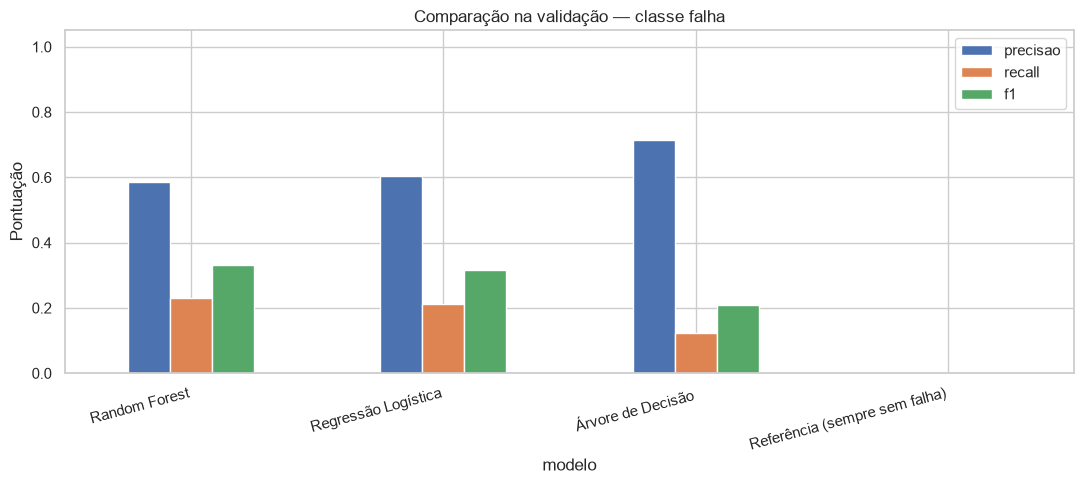

In [14]:
comparacao[["precisao", "recall", "f1"]].plot(kind="bar", figsize=(11, 5), ylim=(0, 1.05))
plt.title("Comparação na validação — classe falha")
plt.ylabel("Pontuação")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## Interpretação das métricas
- **Acurácia:** proporção de registros classificados corretamente.
- **Precisão:** entre os registros classificados como falha, quantos realmente apresentavam falha.
- **Recall:** entre os registros com falha, quantos foram identificados pelo modelo.
- **F1-score:** medida que combina precisão e recall por meio da média harmônica.

Na manutenção industrial, um falso positivo pode gerar inspeções ou paradas
desnecessárias. Um falso negativo representa uma falha que não foi identificada
e pode comprometer o funcionamento do equipamento. A base não contém informações
sobre os custos desses erros, portanto a comparação considera as métricas de classificação.


,teste_final
acuracia,0.8250
precisao,0.5844
recall,0.2394
f1,0.3396


              precision    recall  f1-score   support

   Sem falha       0.85      0.96      0.90       812
   Com falha       0.58      0.24      0.34       188

    accuracy                           0.82      1000
   macro avg       0.71      0.60      0.62      1000
weighted avg       0.80      0.82      0.79      1000



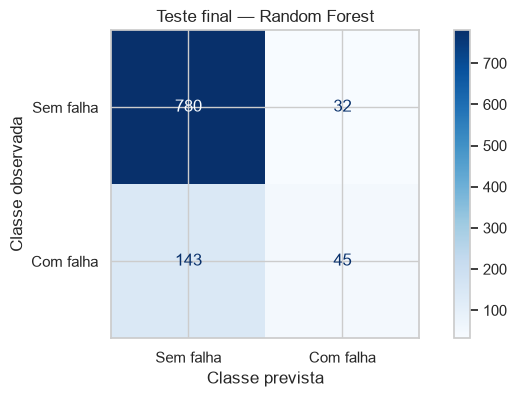

No teste, o modelo **Random Forest** identificou **45** registros com falha e deixou passar **143**. Houve **32** alarmes em registros sem falha. O recall foi **23.94%** e o F1 foi **0.340**. Esses números se referem somente ao período de teste.

**Limitação prática:** o modelo deixou passar **76.06%** das falhas do teste. Esse resultado exige melhoria e nova validação antes de considerar seu uso como único critério de alerta. Para comparação, responder sempre sem falha teria acurácia de **81.20%** neste mesmo teste.

In [15]:
# Treinamento do modelo escolhido com treino e validação
# O conjunto de teste permanece reservado para a avaliação final
from sklearn.base import clone
modelo_final = clone(modelos[nome_escolhido])
desenvolvimento = pd.concat([treino, validacao])
modelo_final.fit(desenvolvimento[numericas], desenvolvimento["falha"])
previsoes_teste = modelo_final.predict(X_teste)
metricas_teste = calcular_metricas(y_teste, previsoes_teste)
display(pd.Series(metricas_teste, name="teste_final").round(4).to_frame())
print(classification_report(y_teste, previsoes_teste, labels=[0, 1],
                            target_names=["Sem falha", "Com falha"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_teste, previsoes_teste, labels=[0, 1],
                                        display_labels=["Sem falha", "Com falha"], cmap="Blues")
plt.xlabel("Classe prevista")
plt.ylabel("Classe observada")
plt.title(f"Teste final — {nome_escolhido}")
plt.show()
tn, fp, fn, tp = confusion_matrix(y_teste, previsoes_teste, labels=[0, 1]).ravel()
display(Markdown(f"No teste, o modelo **{nome_escolhido}** identificou **{tp}** registros com falha "
                 f"e deixou passar **{fn}**. Houve **{fp}** alarmes em registros sem falha. "
                 f"O recall foi **{metricas_teste['recall']:.2%}** e o F1 foi "
                 f"**{metricas_teste['f1']:.3f}**. Esses números se referem somente ao período de teste."))
display(Markdown(f"**Limitação prática:** o modelo deixou passar "
                 f"**{fn / (fn + tp):.2%}** das falhas do teste. "
                 "Esse resultado exige melhoria e nova validação antes de considerar seu uso "
                 "como único critério de alerta. Para comparação, responder sempre sem falha "
                 f"teria acurácia de **{1 - y_teste.mean():.2%}** neste mesmo teste."))


## Resultado da classificação e importância dos atributos
A Random Forest apresentou o maior F1 na validação, aproximadamente 0,332.
Após o treinamento com os conjuntos de treino e validação, o modelo foi avaliado
no conjunto de teste.

Para analisar a contribuição dos atributos, foi utilizada a importância por
permutação na validação, com os modelos ajustados somente no treino. Esse procedimento
embaralha os valores de uma coluna e mede a queda do F1. Uma queda maior indica
que o atributo teve mais influência nas classificações daquele modelo.

Importâncias próximas de zero ou negativas devem ser interpretadas com cuidado,
pois atributos relacionados entre si podem compartilhar informação.


,Árvore de Decisão,Random Forest,Regressão Logística
temperatura_c,0.1235,0.0698,0.0002
vibracao_mm_s,0.0850,0.1448,0.1587
pressao_bar,-0.0007,-0.0276,-0.0070
corrente_a,0.0575,0.0420,0.0373
horas_operacao,0.1296,0.1858,0.2080


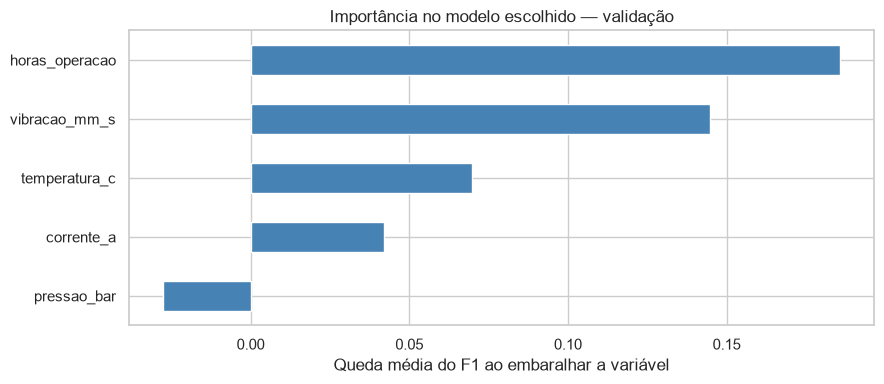

In [16]:
importancias_modelos = {}
for nome in ["Árvore de Decisão", "Random Forest", "Regressão Logística"]:
    importancia = permutation_importance(modelos[nome], X_validacao, y_validacao,
                                         scoring="f1", n_repeats=5, random_state=SEMENTE)
    importancias_modelos[nome] = importancia.importances_mean
tabela_importancias = pd.DataFrame(importancias_modelos, index=numericas)
display(tabela_importancias.round(4))
importancias = tabela_importancias[nome_escolhido].sort_values(ascending=False) if nome_escolhido in tabela_importancias else pd.Series(0.0, index=numericas)
importancias.sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Queda média do F1 ao embaralhar a variável")
plt.title("Importância no modelo escolhido — validação")
plt.tight_layout()
plt.show()


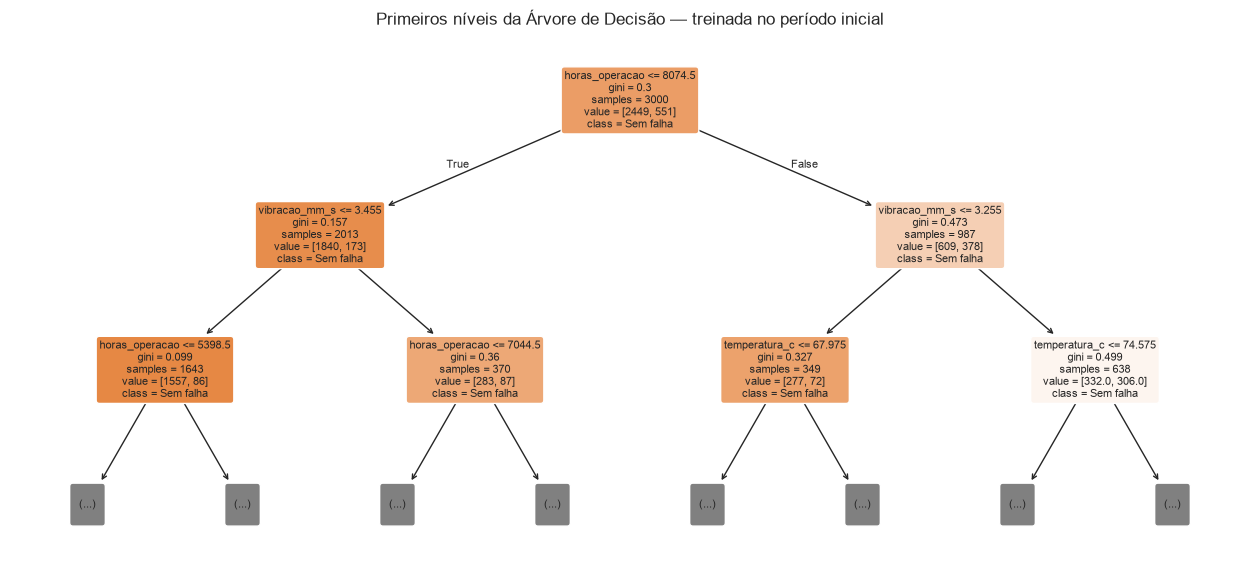

In [17]:
# Visualização dos primeiros níveis da árvore
plt.figure(figsize=(16, 7))
plot_tree(modelos["Árvore de Decisão"].named_steps["modelo"], feature_names=numericas,
          class_names=["Sem falha", "Com falha"], filled=True, rounded=True,
          max_depth=2, fontsize=8)
plt.title("Primeiros níveis da Árvore de Decisão — treinada no período inicial")
plt.show()


# Etapa 4 — Machine Learning não supervisionado
O K-Means foi aplicado às cinco variáveis operacionais, após o preenchimento dos
valores ausentes e a padronização. A coluna `falha` não participou da formação dos grupos.
A padronização evita que atributos com valores maiores, como horas de operação,
tenham peso excessivo no cálculo das distâncias.

Foram comparadas quantidades de 2 a 6 clusters, considerando a silhueta e a curva
de inércia do método do cotovelo. A silhueta varia de -1 a 1, sendo que valores
mais altos indicam maior separação entre os grupos. A análise utiliza a base limpa
completa para descrever os perfis operacionais.


,k,inercia,silhueta
0,2,19692.2874,0.2168
1,3,16538.3968,0.2241
2,4,14576.0801,0.1890
3,5,13093.2410,0.1732
4,6,11874.7846,0.1739


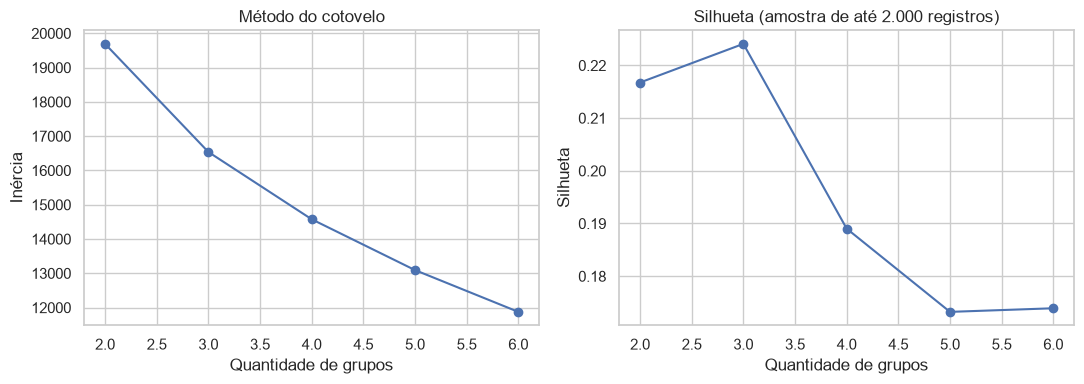

Quantidade escolhida: 3


In [18]:
preparacao_clusters = Pipeline([
    ("ausentes", SimpleImputer(strategy="median")),
    ("escala", StandardScaler())])
X_clusters = preparacao_clusters.fit_transform(df1[numericas])
resultados_k = []
for k in range(2, 7):
    agrupador = KMeans(n_clusters=k, n_init=10, random_state=SEMENTE)
    grupos = agrupador.fit_predict(X_clusters)
    silhueta = silhouette_score(X_clusters, grupos, sample_size=min(2000, len(df1)), random_state=SEMENTE)
    resultados_k.append({"k": k, "inercia": agrupador.inertia_, "silhueta": silhueta})
tabela_k = pd.DataFrame(resultados_k)
display(tabela_k.round(4))
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(tabela_k["k"], tabela_k["inercia"], marker="o")
eixos[0].set(title="Método do cotovelo", xlabel="Quantidade de grupos", ylabel="Inércia")
eixos[1].plot(tabela_k["k"], tabela_k["silhueta"], marker="o")
eixos[1].set(title="Silhueta (amostra de até 2.000 registros)", xlabel="Quantidade de grupos", ylabel="Silhueta")
plt.tight_layout()
plt.show()
k_escolhido = int(tabela_k.loc[tabela_k["silhueta"].idxmax(), "k"])
print("Quantidade escolhida:", k_escolhido)


,temperatura_c,vibracao_mm_s,pressao_bar,corrente_a,horas_operacao
cluster,,,,,
0,64.93,2.56,6.47,24.65,3465.17
1,67.90,3.57,6.53,26.71,8780.33
2,208.28,2.98,6.64,25.89,5899.32


,registros,falhas,taxa
cluster,,,
0,2509,112,0.0446
1,2466,788,0.3195
2,25,3,0.1200


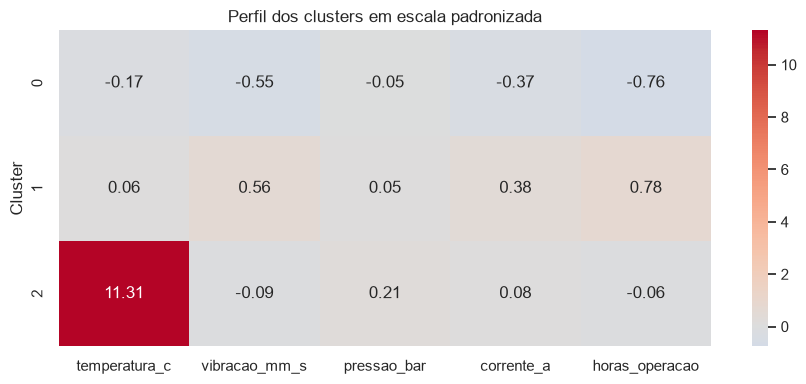

In [19]:
kmeans = KMeans(n_clusters=k_escolhido, n_init=10, random_state=SEMENTE)
df_clusters = df1.copy()
df_clusters["cluster"] = kmeans.fit_predict(X_clusters)
perfil_clusters = df_clusters.groupby("cluster")[numericas].mean()
resumo_clusters = df_clusters.groupby("cluster")["falha"].agg(registros="count", falhas="sum", taxa="mean")
display(perfil_clusters.round(2))
display(resumo_clusters.round(4))

# Centros em desvios-padrão permitem comparar variáveis de unidades diferentes
sns.heatmap(pd.DataFrame(kmeans.cluster_centers_, columns=numericas), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil dos clusters em escala padronizada")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


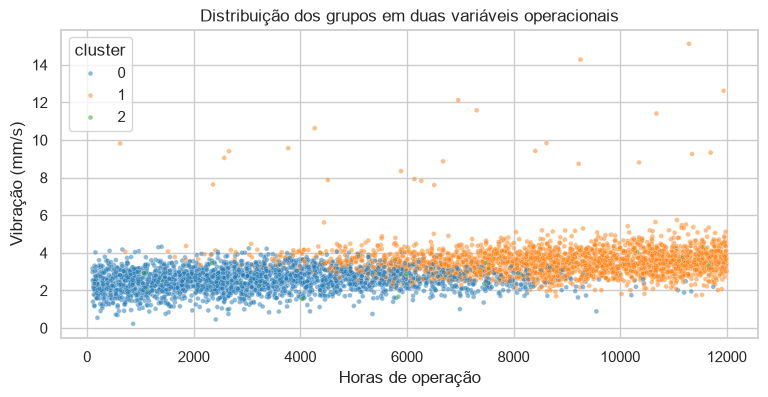

O cluster **1** tem a maior taxa observada de falhas: **31.95%**, em **2466** registros. Os grupos podem apoiar a identificação de perfis que merecem investigação. O número do cluster é apenas um identificador, sem ordem de gravidade.

Perfil do cluster 0: horas_operacao: média 3465.17 (abaixo da média após imputação); vibracao_mm_s: média 2.56 (abaixo da média após imputação).
Perfil do cluster 1: horas_operacao: média 8780.33 (acima da média após imputação); vibracao_mm_s: média 3.57 (acima da média após imputação).
Perfil do cluster 2: temperatura_c: média 208.28 (acima da média após imputação); pressao_bar: média 6.64 (acima da média após imputação).


A silhueta escolhida foi **0.224**. Esse valor ainda indica sobreposição entre perfis; os grupos não são categorias definitivas. O cluster **2** apresenta a maior temperatura média (**208.28 °C**) e tem **25** registros. Os extremos de temperatura podem influenciar a formação dos grupos e precisam ser verificados.

In [20]:
# Duas variáveis em suas unidades originais facilitam a leitura dos perfis
sns.scatterplot(data=df_clusters, x="horas_operacao", y="vibracao_mm_s",
                hue="cluster", palette="tab10", s=12, alpha=0.5)
plt.xlabel("Horas de operação")
plt.ylabel("Vibração (mm/s)")
plt.title("Distribuição dos grupos em duas variáveis operacionais")
plt.show()

cluster_maior_taxa = int(resumo_clusters["taxa"].idxmax())
display(Markdown(f"O cluster **{cluster_maior_taxa}** tem a maior taxa observada de falhas: "
                 f"**{resumo_clusters.loc[cluster_maior_taxa, 'taxa']:.2%}**, em "
                 f"**{int(resumo_clusters.loc[cluster_maior_taxa, 'registros'])}** registros. "
                 "Os grupos podem apoiar a identificação de perfis que merecem investigação. "
                 "O número do cluster é apenas um identificador, sem ordem de gravidade."))
for grupo in perfil_clusters.index:
    centro = pd.Series(kmeans.cluster_centers_[grupo], index=numericas)
    destaques = centro.abs().nlargest(2).index
    descricao = "; ".join(f"{coluna}: média {perfil_clusters.loc[grupo, coluna]:.2f} "
                          f"({'acima' if centro[coluna] > 0 else 'abaixo'} da média após imputação)"
                          for coluna in destaques)
    print(f"Perfil do cluster {grupo}: {descricao}.")
silhueta_escolhida = float(tabela_k.loc[tabela_k["k"] == k_escolhido, "silhueta"].iloc[0])
grupo_temperatura = int(perfil_clusters["temperatura_c"].idxmax())
display(Markdown(f"A silhueta escolhida foi **{silhueta_escolhida:.3f}**. "
                 "Esse valor ainda indica sobreposição entre perfis; os grupos não são categorias definitivas. "
                 f"O cluster **{grupo_temperatura}** apresenta a maior temperatura média "
                 f"(**{perfil_clusters.loc[grupo_temperatura, 'temperatura_c']:.2f} °C**) e tem "
                 f"**{int(resumo_clusters.loc[grupo_temperatura, 'registros'])}** registros. "
                 "Os extremos de temperatura podem influenciar a formação dos grupos e precisam ser verificados."))


## Interpretação dos agrupamentos
Foram selecionados três clusters. O cluster 0 apresentou menores médias de horas
de operação e vibração, com taxa de falha de aproximadamente 4,46%. O cluster 1
apresentou maiores médias dessas variáveis e taxa de falha de 31,95%.

O cluster 2 reuniu apenas 25 registros, com temperatura média de 208,28 °C.
Esse resultado mostra a influência dos valores extremos na formação dos grupos
e reforça a necessidade de verificar essas medições. Sua taxa de falha foi de 12%.

Os agrupamentos podem ajudar a comparar perfis de funcionamento e indicar condições
que merecem acompanhamento. Entretanto, os números dos clusters são apenas
identificadores. As taxas de falha foram calculadas depois da formação dos grupos
e não foram utilizadas pelo K-Means no ajuste.

A silhueta de aproximadamente 0,224 indica que ainda há sobreposição entre os
perfis. O gráfico de dispersão representa somente duas das cinco variáveis utilizadas.


# Etapa 5 — Big Data e tomada de decisão
O PySpark foi utilizado para importar a base, verificar a estrutura das colunas,
selecionar atributos, filtrar registros e calcular indicadores por máquina e por dia.
Os resultados agregados foram comparados com os obtidos no Pandas.

O processamento foi executado em modo local. Como a base possui cerca de 5 mil
registros, essa etapa apresenta as operações do Spark sem medir ganhos de desempenho
em uma infraestrutura distribuída.


In [21]:
import os
from pyspark.sql import SparkSession, functions as F

# Usar o mesmo Python no processo principal e nos trabalhadores locais
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
spark = (SparkSession.builder.master("local[2]")
         .appName("ProjetoManutencaoIndustrial")
         .config("spark.sql.shuffle.partitions", "4")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Versão do Spark:", spark.version)

spark_original = spark.read.option("header", True).option("inferSchema", True).csv(str(arquivo.resolve()))
spark_original.printSchema()
spark_original.show(5, truncate=False)
print("Registros originais:", spark_original.count())


Versão do Spark: 4.0.1


root
 |-- timestamp: timestamp (nullable = true)
 |-- maquina_id: string (nullable = true)
 |-- temperatura_c: double (nullable = true)
 |-- vibracao_mm_s: double (nullable = true)
 |-- pressao_bar: double (nullable = true)
 |-- corrente_a: double (nullable = true)
 |-- horas_operacao: integer (nullable = true)
 |-- falha: integer (nullable = true)

+-------------------+----------+-------------+-------------+-----------+----------+--------------+-----+
|timestamp          |maquina_id|temperatura_c|vibracao_mm_s|pressao_bar|corrente_a|horas_operacao|falha|
+-------------------+----------+-------------+-------------+-----------+----------+--------------+-----+
|2026-02-05 18:00:00|M04       |61.97        |3.37         |5.59       |22.48     |10154         |0    |
|2026-01-22 13:00:00|M01       |60.86        |2.07         |6.55       |23.21     |2687          |0    |
|2026-01-17 05:00:00|M03       |70.35        |2.75         |6.21       |26.36     |11779         |0    |
|2026-01-19 16:00:

Registros originais: 5050


In [22]:
# Limpeza e conferência da mesma fonte de dados
spark_limpo = spark_original.dropDuplicates().withColumn("timestamp", F.to_timestamp("timestamp"))
print("Registros após remover duplicatas:", spark_limpo.count())
spark_limpo.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in colunas_esperadas]).show()

# Seleção de colunas e filtro por falha
spark_limpo.select("timestamp", "maquina_id", "temperatura_c", "vibracao_mm_s", "falha").show(5)
spark_limpo.filter(F.col("falha") == 1).select("maquina_id", "temperatura_c", "vibracao_mm_s").show(5)

# Agrupamento por máquina: média de 0/1 equivale à taxa de falhas
taxas_spark = (spark_limpo.groupBy("maquina_id")
               .agg(F.count("*").alias("registros"), F.sum("falha").alias("falhas"),
                    F.avg("falha").alias("taxa"))
               .orderBy(F.desc("taxa")))
taxas_spark.show()

# Médias dos sensores por classe e quantidade de registros por dia
spark_limpo.groupBy("falha").agg(*[F.avg(c).alias("media_" + c) for c in numericas]).show()
spark_limpo.groupBy(F.to_date("timestamp").alias("dia")).agg(
    F.count("*").alias("registros"), F.sum("falha").alias("falhas")).orderBy("dia").show(7)


Registros após remover duplicatas: 5000


+---------+----------+-------------+-------------+-----------+----------+--------------+-----+
|timestamp|maquina_id|temperatura_c|vibracao_mm_s|pressao_bar|corrente_a|horas_operacao|falha|
+---------+----------+-------------+-------------+-----------+----------+--------------+-----+
|        0|         0|           50|           50|         50|        50|            50|    0|
+---------+----------+-------------+-------------+-----------+----------+--------------+-----+



+-------------------+----------+-------------+-------------+-----+
|          timestamp|maquina_id|temperatura_c|vibracao_mm_s|falha|
+-------------------+----------+-------------+-------------+-----+
|2026-02-11 02:00:00|       M05|        72.44|         2.19|    0|
|2026-02-09 18:00:00|       M02|        58.58|         3.46|    0|
|2026-02-07 18:00:00|       M05|        58.34|         4.14|    0|
|2026-01-10 06:00:00|       M02|        62.88|         3.68|    1|
|2026-01-26 00:00:00|       M05|        57.12|         1.73|    0|
+-------------------+----------+-------------+-------------+-----+
only showing top 5 rows


+----------+-------------+-------------+
|maquina_id|temperatura_c|vibracao_mm_s|
+----------+-------------+-------------+
|       M02|        62.88|         3.68|
|       M05|        67.27|         3.74|
|       M01|        62.25|         3.73|
|       M05|        72.71|         3.53|
|       M02|        73.78|         3.66|
+----------+-------------+-------------+
only showing top 5 rows


+----------+---------+------+-----+
|maquina_id|registros|falhas| taxa|
+----------+---------+------+-----+
|       M04|     1000|   189|0.189|
|       M03|     1000|   181|0.181|
|       M05|     1000|   180| 0.18|
|       M02|     1000|   178|0.178|
|       M01|     1000|   175|0.175|
+----------+---------+------+-----+



+-----+-------------------+-------------------+-----------------+-----------------+--------------------+
|falha|media_temperatura_c|media_vibracao_mm_s|media_pressao_bar| media_corrente_a|media_horas_operacao|
+-----+-------------------+-------------------+-----------------+-----------------+--------------------+
|    0|    66.459236453202|  2.928238776517019|6.507532051282088|25.46358392901156|   5483.839990138067|
|    1|  70.10932584269668| 3.6425111607142786|6.470961968680087|26.61400895856661|   8887.348993288591|
+-----+-------------------+-------------------+-----------------+-----------------+--------------------+



+----------+---------+------+
|       dia|registros|falhas|
+----------+---------+------+
|2026-01-01|      120|    19|
|2026-01-02|      120|    24|
|2026-01-03|      120|    20|
|2026-01-04|      120|    24|
|2026-01-05|      120|    30|
|2026-01-06|      120|    23|
|2026-01-07|      120|    20|
+----------+---------+------+
only showing top 7 rows


In [23]:
# Conferindo a consistência dos resultados de Pandas e Spark
assert spark_original.count() == len(df)
assert spark_limpo.count() == len(df1)
taxas_conferencia = taxas_spark.toPandas().set_index("maquina_id").sort_index()
assert np.allclose(taxas_conferencia["taxa"], taxas.sort_index()["taxa"])
print("Conferência concluída: contagens e taxas por máquina coincidem.")
spark.stop()


Conferência concluída: contagens e taxas por máquina coincidem.


## Comparação entre Pandas e PySpark
| Aspecto | Pandas | PySpark |
|---|---|---|
| Processamento | Utiliza os recursos de uma máquina | Pode distribuir o trabalho entre máquinas de um cluster |
| Execução | Operações comuns retornam o resultado imediatamente | Transformações são planejadas; ações como `count` e `show` iniciam a execução |
| Aplicação neste projeto | Exploração, gráficos e preparação para os modelos | Leitura, seleção, filtros e agrupamentos |
| Volume de dados | Limitado principalmente pela memória disponível | Pode utilizar partições e armazenamento distribuído |

As contagens de registros e as taxas de falha por máquina coincidiram nas duas
ferramentas. A conversão com `toPandas` foi aplicada apenas ao resumo das cinco máquinas.

Em uma operação com mais equipamentos e sensores, o processamento distribuído
poderia dividir as tarefas de leitura, limpeza e agregação entre várias máquinas.
Para a base utilizada, o Pandas foi suficiente. Não foi realizada uma comparação
de tempo de execução, e o uso local do Spark não permite concluir que houve ganho de desempenho.


# 6. Entregáveis do projeto e recomendações finais


### 6.1 Objetivo do estudo

A S&M Industry Tech enfrenta paradas não planejadas de equipamentos. O estudo utilizou o histórico de operação das máquinas para investigar as condições associadas às falhas e avaliar como os dados podem apoiar a equipe de manutenção.

O trabalho reúne exploração e preparação dos dados, classificação com Machine Learning, agrupamento com K-Means e operações com PySpark. Este relatório consolida os resultados dessas etapas e apresenta recomendações baseadas nas evidências encontradas.

A análise considera a ocorrência de falha no próprio registro. A base utilizada não define um intervalo de antecedência para previsão. Portanto, os resultados representam a classificação das condições registradas e não uma demonstração de que a falha pode ser prevista horas antes de acontecer.

### 6.2 Base de dados e preparação

O arquivo original contém 5.050 registros e 8 atributos. As colunas são data e hora, identificação da máquina, temperatura, vibração, pressão, corrente elétrica, horas de operação e ocorrência de falha. O período observado vai de 1º de janeiro a 11 de fevereiro de 2026 e abrange cinco máquinas, identificadas de M01 a M05.

| Verificação | Resultado | Tratamento adotado |
| :--- | :--- | :--- |
| Duplicatas exatas | 50 registros | Remoção das linhas repetidas |
| Tamanho após a limpeza | 5.000 registros | Base utilizada nas análises seguintes |
| Valores ausentes após retirar duplicatas | 50 em cada uma das cinco variáveis operacionais | Mediana aprendida no treinamento dos classificadores |
| Datas | Sem valores inválidos após a conversão | Conversão para data e hora e ordenação temporal |
| Valores extremos | Temperatura máxima de 278,84 °C e vibração máxima de 15,12 mm/s | Sinalização para investigação, sem exclusão automática |

A retirada de duplicatas evita a contagem repetida de uma mesma observação. O preenchimento pela mediana mantém os registros com ausências e reduz a influência dos extremos em comparação com a média. Nos classificadores, o cálculo da mediana foi feito dentro do Pipeline, utilizando apenas os dados disponíveis para treinamento em cada ajuste.

Os outliers foram mantidos porque os limites técnicos dos equipamentos não constam na base. Uma medição elevada pode indicar uma situação de operação relevante ou um problema no sensor. Excluir esses valores sem investigação poderia retirar informações importantes sobre as falhas.

### 6.3 Principais descobertas

#### Frequência de falhas e comparação entre máquinas

Após a limpeza, 903 registros apresentaram falha, equivalentes a **18,06%** da base. Os outros 4.097 registros, ou **81,94%**, não apresentaram falha. Esse desequilíbrio exige cuidado com a acurácia: acertar a classe mais frequente pode gerar um percentual alto de acertos sem identificar as falhas.

| Máquina | Registros | Registros com falha | Taxa de falha |
| :--- | ---: | ---: | ---: |
| M01 | 1.000 | 175 | 17,50% |
| M02 | 1.000 | 178 | 17,80% |
| M03 | 1.000 | 181 | 18,10% |
| M04 | 1.000 | 189 | 18,90% |
| M05 | 1.000 | 180 | 18,00% |

A M04 apresentou a maior taxa observada. A diferença para a M01, que teve a menor taxa, foi de 1,40 ponto percentual. Esse resultado justifica uma investigação do histórico da M04, mas não comprova que a máquina seja menos confiável. As condições de uso e as intervenções realizadas também precisam ser consideradas.

#### Condições operacionais associadas às falhas

| Variável | Média sem falha | Média com falha | Correlação com falha |
| :--- | ---: | ---: | ---: |
| Temperatura (°C) | 66,46 | 70,11 | 0,112 |
| Vibração (mm/s) | 2,93 | 3,64 | 0,304 |
| Pressão (bar) | 6,51 | 6,47 | -0,022 |
| Corrente elétrica (A) | 25,46 | 26,61 | 0,163 |
| Horas de operação | 5.483,84 | 8.887,35 | 0,381 |

As horas de operação e a vibração apresentaram as maiores correlações lineares com a falha. As médias dessas variáveis também foram maiores nos registros com falha. Temperatura e corrente elétrica apresentaram associação positiva mais fraca. A pressão teve pouca correlação linear com o alvo.

Esses resultados indicam que o acompanhamento conjunto das medições pode ser mais útil que a observação isolada de um sensor. A correlação, entretanto, não demonstra causa e efeito e não fornece, sozinha, um limite seguro para emitir alertas.

### 6.4 Modelo de classificação escolhido

Os atributos utilizados foram temperatura, vibração, pressão, corrente elétrica e horas de operação. O alvo foi a coluna `falha`. A identificação da máquina ficou fora do treinamento para concentrar a análise nas medições operacionais. A data serviu para organizar a divisão dos dados.

A separação respeitou a ordem temporal, com 3.000 registros para treino, 1.000 para validação e 1.000 para teste. Os modelos aprenderam com o período inicial e a avaliação final utilizou o período mais recente. Registros do mesmo instante permaneceram no mesmo conjunto.

Foram comparados Árvore de Decisão, Random Forest e Regressão Logística. Um classificador que sempre escolhe a classe mais frequente serviu de referência. O critério de escolha foi o F1-score da classe falha na validação, com recall como desempate.

| Modelo | Acurácia na validação | Precisão | Recall | F1-score |
| :--- | ---: | ---: | ---: | ---: |
| Random Forest | 84,70% | 58,46% | 23,17% | **0,332** |
| Regressão Logística | 84,80% | 60,34% | 21,34% | 0,315 |
| Árvore de Decisão | 84,80% | 71,43% | 12,20% | 0,208 |
| Referência: classe mais frequente | 83,60% | 0,00% | 0,00% | 0,000 |

A **Random Forest** apresentou o maior F1 na validação. Após essa escolha, o modelo foi treinado novamente com treino e validação reunidos. O teste permaneceu separado até a avaliação final.

| Métrica no teste | Resultado | Interpretação |
| :--- | ---: | :--- |
| Acurácia | 82,50% | 825 classificações corretas entre 1.000 registros |
| Precisão | 58,44% | 45 falhas confirmadas entre 77 registros classificados como falha |
| Recall | 23,94% | 45 falhas identificadas entre 188 existentes |
| F1-score | 0,340 | Equilíbrio ainda limitado entre precisão e recall |

As horas de operação tiveram a maior importância por permutação na validação para a Random Forest, seguidas pela vibração. Essa importância representa a redução do F1 ao embaralhar os valores de uma variável, mantendo as demais condições da avaliação.

### 6.5 Erros do modelo e consequências para a manutenção

| Situação observada | Previsão: sem falha | Previsão: com falha | Total |
| :--- | ---: | ---: | ---: |
| Sem falha | 780 | 32 | 812 |
| Com falha | 143 | 45 | 188 |
| Total | 923 | 77 | 1.000 |

Os **32 falsos positivos** representam registros sem falha que receberam classificação de falha. Em uma aplicação de manutenção, esse tipo de erro poderia gerar inspeções ou paradas desnecessárias.

Os **143 falsos negativos** representam falhas que o modelo não identificou. Isso corresponde a **76,06% das falhas do teste**. Esse foi o principal problema encontrado na classificação, pois limita a capacidade de detectar situações que exigem atenção.

Uma classificação constante de “sem falha” teria acurácia de 81,20% nesse mesmo teste. A acurácia de 82,50% da Random Forest ficou apenas 1,30 ponto percentual acima dessa referência. Por isso, a escolha do melhor modelo entre os candidatos não significa que o desempenho já seja suficiente para uso operacional.

O modelo precisa melhorar e passar por novas avaliações antes de funcionar como único critério de alerta. A base não informa os custos dos erros, portanto não permite calcular economia, prejuízo evitado ou retorno financeiro.

### 6.6 Perfis identificados pelo K-Means

O K-Means utilizou as cinco variáveis operacionais, com preenchimento dos ausentes e padronização. O alvo `falha` não participou do ajuste. As taxas de falha foram calculadas somente depois da formação dos grupos.

Foram comparadas quantidades de 2 a 6 clusters. A melhor silhueta entre os candidatos ocorreu com três grupos, com valor aproximado de 0,224. Esse resultado indica que ainda existe sobreposição entre os perfis.

| Cluster | Registros | Taxa de falha | Características observadas |
| :--- | ---: | ---: | :--- |
| 0 | 2.509 | 4,46% | Menores médias de horas de operação e vibração |
| 1 | 2.466 | 31,95% | Maiores médias de horas de operação e vibração |
| 2 | 25 | 12,00% | Temperatura média de 208,28 °C |

O cluster 1 concentrou uma proporção maior de falhas e pode orientar a investigação de condições de operação que merecem acompanhamento. Isso não significa que todo registro desse perfil apresente falha.

O cluster 2 mostrou como os extremos de temperatura influenciaram o agrupamento. Antes de tratar esse grupo como um perfil de operação, é necessário conferir os sensores e a consistência dessas medições. Os números dos clusters são apenas identificadores e não representam uma escala de gravidade.

### 6.7 Contribuição do PySpark

O PySpark realizou leitura do CSV, inspeção do schema, remoção de duplicatas, seleção de colunas, filtro dos registros com falha e agrupamentos por máquina, classe e dia. As contagens e taxas por máquina coincidiram com os resultados do Pandas.

A execução utilizou modo local. Como a base possui cerca de 5 mil registros, o Pandas foi suficiente para as análises realizadas. O trabalho não mediu desempenho em um cluster e não demonstrou ganho de velocidade com processamento distribuído.

Em uma coleta com mais equipamentos, sensores e registros frequentes, o Spark poderia dividir as tarefas de leitura, limpeza e agregação entre várias máquinas. Essa possibilidade depende da infraestrutura disponível e do volume de dados.

### 6.8 Recomendações técnicas

As ações abaixo são propostas baseadas na análise. Não representam intervenções já realizadas nem resultados operacionais comprovados.

| Prioridade proposta | Evidência | Ação recomendada | Forma de acompanhamento |
| :--- | :--- | :--- | :--- |
| Inicial | Ausências nas cinco variáveis operacionais | Verificar falhas de coleta e registrar a origem das ausências | Percentual de ausências por sensor e por máquina |
| Inicial | Temperaturas extremas e cluster com apenas 25 registros | Conferir calibração, unidade de medida e histórico das medições | Quantidade de extremos confirmados e corrigidos |
| Inicial | Maiores associações de horas de operação e vibração com falha | Acompanhar essas variáveis junto com temperatura e corrente | Evolução das medições e falhas confirmadas em cada condição |
| Inicial | M04 com taxa de 18,90% | Examinar histórico de uso, intervenções e condições de operação da M04 | Taxas por equipamento em períodos comparáveis |
| Desenvolvimento | Recall de 23,94% no teste | Avaliar ajustes de pesos das classes, parâmetros e limite de decisão usando dados de desenvolvimento | Recall, precisão, F1 e volume de alertas em nova avaliação |
| Desenvolvimento | Poucas informações sobre as intervenções | Registrar manutenção realizada, causa confirmada e componente afetado | Completude dos registros e confirmação dos rótulos de falha |
| Validação futura | Base de cinco máquinas e período curto | Ampliar a coleta e reservar novos períodos para teste | Desempenho por período e por equipamento |

Os ajustes propostos para o classificador são possibilidades para uma próxima análise, não melhorias já testadas neste trabalho. O teste atual não deve orientar novas escolhas de parâmetros. Após novos ajustes, será necessário avaliar o desempenho em dados ainda não utilizados.

Não foi definido um limite fixo de temperatura ou vibração para parada de máquina. Esse limite depende das especificações do fabricante, das condições de operação e da avaliação da equipe técnica.

### 6.9 Limitações

- O histórico abrange cinco máquinas e aproximadamente seis semanas, o que limita as conclusões sobre outros períodos ou equipamentos.
- A base não apresenta os limites técnicos de operação, as causas confirmadas das falhas nem os detalhes das intervenções.
- A manutenção dos outliers evita descartar sinais relevantes, mas pode influenciar as correlações e os agrupamentos.
- O recall baixo indica que grande parte das falhas passou sem identificação.
- As relações encontradas são associações e não comprovam causas físicas das falhas.
- O alvo descreve a falha no registro atual. Prever com antecedência exige definir um horizonte futuro e utilizar apenas informações anteriores a ele.
- O Spark foi utilizado localmente, sem comparação de desempenho distribuído.

### 6.10 Conclusão

O projeto mostrou que os dados operacionais podem ajudar a compreender as condições associadas às falhas. Horas de operação e vibração se destacaram tanto na análise exploratória quanto na importância dos atributos da Random Forest. Os agrupamentos também indicaram diferenças entre perfis com menores e maiores taxas de falha.

A Random Forest obteve o melhor F1 entre os classificadores comparados na validação, mas o resultado do teste evidenciou uma limitação importante: apenas 45 das 188 falhas foram identificadas. Dessa forma, as descobertas descritivas já oferecem pontos de investigação para a manutenção, enquanto a classificação ainda precisa de desenvolvimento e nova validação.

As prioridades propostas são melhorar a qualidade da coleta, verificar medições extremas, acompanhar os sensores em conjunto e registrar melhor as intervenções. Essas ações podem fornecer uma base mais consistente para estudos futuros e para a avaliação de ferramentas de apoio à manutenção.



In [24]:
# Exportação das tabelas de resultados
taxas.to_csv("resultados/taxas_por_maquina.csv", encoding="utf-8-sig")
resumo_clusters.join(perfil_clusters).to_csv("resultados/perfis_clusters.csv", encoding="utf-8-sig")
tabela_importancias.to_csv("resultados/importancias_validacao.csv", encoding="utf-8-sig")
Path("resultados/metricas_teste.json").write_text(json.dumps({
    "modelo": nome_escolhido, **metricas_teste,
    "verdadeiros_negativos": int(tn), "falsos_positivos": int(fp),
    "falsos_negativos": int(fn), "verdadeiros_positivos": int(tp)},
    ensure_ascii=False, indent=2), encoding="utf-8")


263

## Referências
- Material da disciplina: **Projeto Pós Data Science e BigData**, Prof. Me. Daniel Vieira.
- [Base de dados de manutenção](https://drive.google.com/file/d/1yQ7P-mbRK3Gsh12ey6ahxk8szc6pOie1/view).
- [Documentação do Pandas](https://pandas.pydata.org/docs/).
- [Documentação do scikit-learn](https://scikit-learn.org/stable/user_guide.html).
- [Documentação do PySpark](https://spark.apache.org/docs/4.0.1/api/python/index.html).
